<a href="https://colab.research.google.com/github/saichandanss2190/ITA0615-Machine-Learning-192312190-/blob/main/Exp_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

       LINEAR REGRESSION RESULTS (FROM SCRATCH)     
Estimated Slope (Weight) : 2.2701 (True: 2.5)
Estimated Intercept (Bias): 15.2151 (True: 15.0)
--------------------------------------------------
Mean Squared Error (MSE) : 0.8066
R-squared (R2) Score     : 0.6913


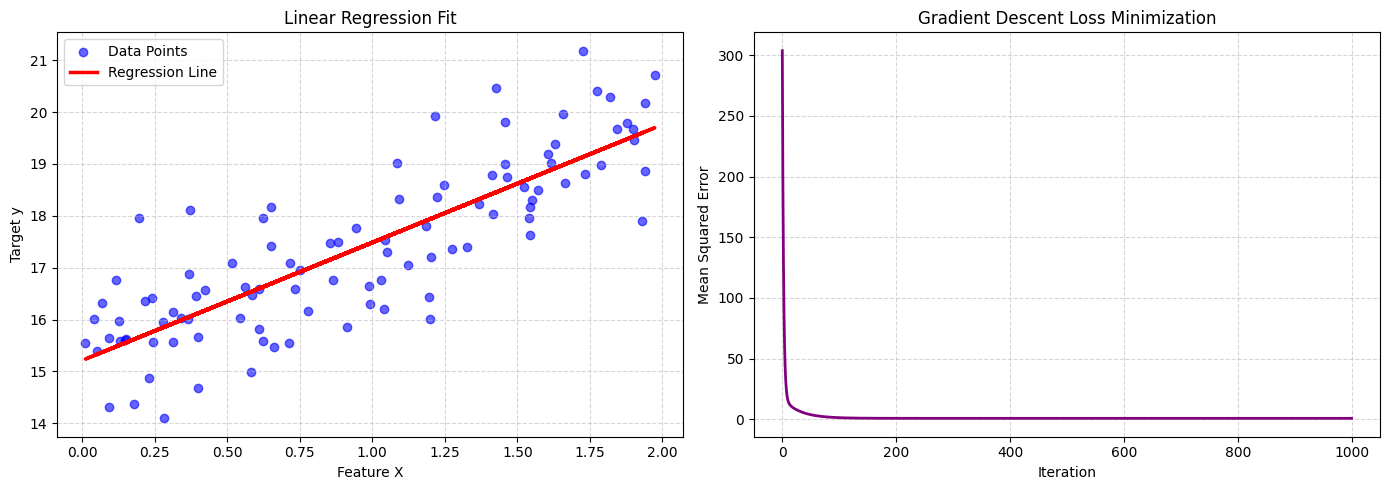

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Set random seed for reproducibility
np.random.seed(42)

# 1. Generate Synthetic Data
# True relationship: y = 2.5 * X + 15
X = 2 * np.random.rand(100, 1)
y = 15 + 2.5 * X + np.random.randn(100, 1)

# 2. Linear Regression Implementation
class LinearRegressionScratch:
    def __init__(self, learning_rate=0.01, iterations=1000):
        self.lr = learning_rate
        self.iterations = iterations
        self.weights = None
        self.bias = None
        self.loss_history = []

    def fit(self, X, y):
        n_samples, n_features = X.shape
        # Initialize parameters
        self.weights = np.zeros((n_features, 1))
        self.bias = 0.0

        # Gradient Descent
        for _ in range(self.iterations):
            y_predicted = np.dot(X, self.weights) + self.bias

            # Calculate gradients
            dw = (1 / n_samples) * np.dot(X.T, (y_predicted - y))
            db = (1 / n_samples) * np.sum(y_predicted - y)

            # Update parameters
            self.weights -= self.lr * dw
            self.bias -= self.lr * db

            # Record loss (Mean Squared Error)
            loss = np.mean((y_predicted - y) ** 2)
            self.loss_history.append(loss)

    def predict(self, X):
        return np.dot(X, self.weights) + self.bias

# 3. Train the Model
model = LinearRegressionScratch(learning_rate=0.1, iterations=1000)
model.fit(X, y)
predictions = model.predict(X)

# 4. Evaluate Performance
mse = np.mean((predictions - y) ** 2)
r2 = 1 - (np.sum((y - predictions) ** 2) / np.sum((y - np.mean(y)) ** 2))

# Presentable Text Output
print("="*50)
print("       LINEAR REGRESSION RESULTS (FROM SCRATCH)     ")
print("="*50)
print(f"Estimated Slope (Weight) : {model.weights[0][0]:.4f} (True: 2.5)")
print(f"Estimated Intercept (Bias): {model.bias:.4f} (True: 15.0)")
print("-"*50)
print(f"Mean Squared Error (MSE) : {mse:.4f}")
print(f"R-squared (R2) Score     : {r2:.4f}")
print("="*50)

# 5. Visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot Regression Line
ax1.scatter(X, y, color='blue', alpha=0.6, label='Data Points')
ax1.plot(X, predictions, color='red', linewidth=2.5, label='Regression Line')
ax1.set_title('Linear Regression Fit')
ax1.set_xlabel('Feature X')
ax1.set_ylabel('Target y')
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.5)

# Plot Loss Curve
ax2.plot(model.loss_history, color='purple', linewidth=2)
ax2.set_title('Gradient Descent Loss Minimization')
ax2.set_xlabel('Iteration')
ax2.set_ylabel('Mean Squared Error')
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()